# Improvements

Notebook 04 found these issues in the six log-return models:

* **Forecast accuracy:** none of the six networks beat the naive or the random walk with drift baselines.
* **Model selection:** the six validation losses differ only in the third decimal, and the selected model (lowest validation loss) ranked fourth of six on the test set.
* **Bias:** every network predicts a fall on most days, while the price rose on 55% of the test days.

CRISP-DM is iterative, so this notebook goes back to **Modeling** with one improvement for the selected model:

**Hyperparameter tuning:** KerasTuner searches units, dropout, learning rate and batch size for the selected model (and the kernel size if it is a CNN), using the validation set only.

The original and the tuned versions are compared by **validation RMSE in dollars**, a rule set before looking at any result. The test set only reports the outcome.

Tuning takes about 20 minutes on a laptop CPU. Set `RETRAIN = False` in `config.py` to reload the saved search and model instead.

[`docs/03_deep_learning_models.md`](../docs/03_deep_learning_models.md)

In [ ]:
""" Notebook setup: make the project's modules (config.py, src/) importable """
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if "TF_CPP_MIN_LOG_LEVEL" not in os.environ:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info/warning logs
if os.name == "nt":  # Windows: expose the conda env's CUDA/cuDNN DLLs so TensorFlow can find the GPU
    os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

import config
from src.data_loader import load_stock_data
from src.evaluate import comparison_table, predict_split
from src.notebook import show_source
from src.predict import load_artifacts, predict_next_day, simulate_recent
from src.train import train_or_load
from src.tuning import TunedModel, run_tuning, best_hparams_from
from src import plotting

plotting.set_plot_style()

2026-11-12 17:09:25.327451: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-12 17:09:25.339682: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-12 17:09:25.339729: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## The selected model
The run with the lowest validation loss, read from `artifacts/metrics.csv` (written by notebook 04). It is reloaded, not retrained.

In [ ]:
metrics = pd.read_csv(config.METRICS_PATH, index_col=0)
selected_run = metrics[metrics["kind"] == "model"]["val_loss"].idxmin()
selected_model_name = metrics.loc[selected_run, "model"]
selected_use_volume = metrics.loc[selected_run, "features"] == "close + volume"

selected = train_or_load(selected_model_name, selected_use_volume, retrain=False)
print("Selected model:", selected_run, "| architecture:", selected_model_name, "| volume:", selected_use_volume)

lstm_close_volume        reloaded (13 epochs, best epoch 3, val_loss 0.3841)
Selected model: lstm_close_volume | architecture: lstm | volume: True


2026-11-12 17:09:26.828499: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:282] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## Hyperparameter tuning with KerasTuner
The search space is defined in `src/tuning.py`. Each of the 20 trials trains with the same callbacks as notebook 03 and is scored by its best validation loss. The best combination is then retrained with `train_model`, so it is saved and evaluated like the other runs.

In [ ]:
show_source(TunedModel)
show_source(run_tuning)


<details>
<summary>View implementation of <code>TunedModel</code></summary>

```python
class TunedModel(keras_tuner.HyperModel):
    """Search space for the selected architecture. Uses training and validation data only."""

    def __init__(self, model_name: str, data: PreparedData):
        super().__init__()
        self.model_name = model_name
        self.data = data

    def build(self, hp):
        return build_model(
            self.model_name,
            self.data.splits["train"].X.shape[1:],
            units=hp.Choice("units", UNITS_CHOICES),
            kernel_size=hp.Choice("kernel_size", KERNEL_SIZE_CHOICES) if self.model_name == "cnn" else config.KERNEL_SIZE,
            dropout=hp.Float("dropout", *DROPOUT_RANGE[:2], step=DROPOUT_RANGE[2]),
            learning_rate=hp.Float("learning_rate", *LEARNING_RATE_RANGE, sampling="log"),
        )

    def fit(self, hp, model, *args, **kwargs):
        train, val = self.data.splits["train"], self.data.splits["val"]
        # shuffle=False keeps the training windows in chronological order, as in train_model.
        return model.fit(train.X, train.y, validation_data=(val.X, val.y),
                         batch_size=hp.Choice("batch_size", BATCH_SIZE_CHOICES), shuffle=False, *args, **kwargs)

```

</details>



<details>
<summary>View implementation of <code>run_tuning</code></summary>

```python
def run_tuning(
    selected_run: str,
    model_name: str,
    data: PreparedData,
    retrain: Optional[bool] = None,
    max_trials: int = config.TUNER_TRIALS,
    tuning_dir: Path = config.TUNING_DIR,
) -> list:
    """
    Run the random search (or reuse its saved results when retrain is False) and
    return the trials sorted from best to worst validation loss.
    """
    retrain = config.RETRAIN if retrain is None else retrain
    results_path = tuning_results_path(selected_run, tuning_dir)

    if retrain:
        keras.utils.set_random_seed(config.SEED)
        tuner = keras_tuner.RandomSearch(
            TunedModel(model_name, data),
            objective="val_loss",
            max_trials=max_trials,
            executions_per_trial=1,
            seed=config.SEED,
            directory=str(tuning_dir),
            project_name=selected_run,
            overwrite=True,
        )
        start = time.time()
        tuner.search(epochs=config.EPOCHS, verbose=0, callbacks=training_callbacks())
        print(f"Tuning finished in {time.time() - start:.0f}s")

        trials = [{**trial.hyperparameters.values, "best val loss": float(trial.score)}
                  for trial in tuner.oracle.get_best_trials(num_trials=max_trials)]
        results_path.parent.mkdir(parents=True, exist_ok=True)
        results_path.write_text(json.dumps(trials, indent=2), encoding="utf-8")

    return json.loads(results_path.read_text(encoding="utf-8"))

```

</details>


In [ ]:
trials = run_tuning(selected_run, selected_model_name, selected.data)
best_hparams = best_hparams_from(trials)

# Retrain the best combination through the same training code, so it is saved and evaluated like the others.
tuned = train_or_load(selected_model_name, selected_use_volume, hparams=best_hparams, suffix="_tuned")
tuned_run = tuned.metadata["run_name"]
print("Best hyperparameters:", best_hparams)
pd.DataFrame(trials).head(10).round(5)

Tuning finished in 431s


lstm_close_volume_tuned   13 epochs, best epoch   3, val_loss 0.3839, 11s
Best hyperparameters: {'units': 64, 'kernel_size': 5, 'dropout': 0.0, 'learning_rate': 0.002793674101922152, 'batch_size': 64}


,units,dropout,learning_rate,batch_size,best val loss
0,64,0.0,0.00279,64,0.38366
1,128,0.2,0.00133,32,0.38389
2,128,0.4,0.00030,16,0.38389
3,32,0.4,0.00167,32,0.38394
4,32,0.2,0.00021,16,0.38398
5,128,0.3,0.00023,16,0.38404
6,32,0.3,0.00233,32,0.38416
7,128,0.4,0.00016,16,0.38426
8,64,0.0,0.00054,64,0.38442
9,64,0.4,0.00045,32,0.38444


## Comparing the two versions
Choose with validation data, in dollars. Report the test set afterward. Both tables are saved to `artifacts/`.

In [ ]:
VERSIONS = {selected_run: selected, tuned_run: tuned}
improvement_validation = comparison_table(VERSIONS, split="val")
improvement_test = comparison_table(VERSIONS, split="test")
improvement_validation.to_csv(config.ARTIFACTS_DIR / "improvements_validation.csv")
improvement_test.to_csv(config.ARTIFACTS_DIR / "improvements_test.csv")

best_version = improvement_validation[improvement_validation["kind"] == "model"]["RMSE"].idxmin()
print("Validation set, in dollars:")
display(improvement_validation.round(4))
print("Best by validation RMSE:", best_version)
print("\nTest set, for reporting only:")
improvement_test.round(4)

Validation set, in dollars:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
lstm_close_volume_tuned,model,2.0363,2.7040,1.2943,53.6508
lstm_close_volume,model,2.0414,2.7048,1.2972,52.5397
baseline: naive (tomorrow = today),baseline,2.0512,2.7110,1.3029,NaN
baseline: random walk + drift,baseline,2.0540,2.7147,1.3049,51.1111
baseline: 5-day moving average,baseline,3.1819,3.9911,2.0092,49.0476


Best by validation RMSE: lstm_close_volume_tuned

Test set, for reporting only:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
baseline: random walk + drift,baseline,2.8363,4.1520,1.1852,55.2215
baseline: naive (tomorrow = today),baseline,2.8533,4.1577,1.1918,NaN
lstm_close_volume,model,2.9574,4.2378,1.2300,44.7785
lstm_close_volume_tuned,model,3.8322,5.0868,1.5465,44.3038
baseline: 5-day moving average,baseline,4.7336,6.4502,1.9777,48.8924


## Historical replay of the two versions
The same next-day prediction and last-20-days replay as notebook 05, for each version of the selected model.

,predicted close,predicted change (%),20-day MAE ($),days predicted too low
run,,,,
lstm_close_volume,328.00,-0.42,3.97,14
lstm_close_volume_tuned,323.31,-1.85,7.09,18


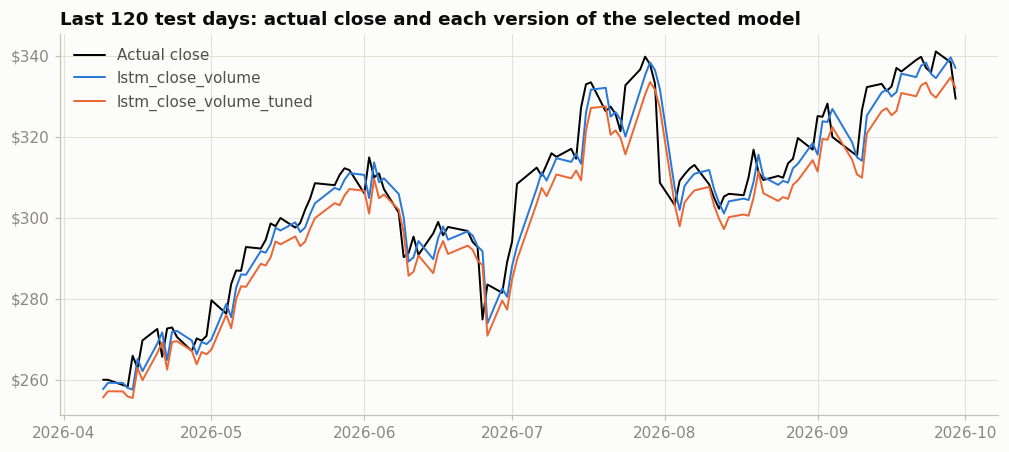

In [ ]:
df = load_stock_data(start_date=None, verbose=False)
rows = []
for name in VERSIONS:
    artifacts = load_artifacts(config.ARTIFACTS_DIR / name)
    next_day = predict_next_day(artifacts, df)
    replay = simulate_recent(artifacts, df, days=20)
    rows.append({"run": name, "predicted close": next_day["predicted_close"],
                 "predicted change (%)": next_day["predicted_change_pct"],
                 "20-day MAE ($)": replay["error ($)"].abs().mean(),
                 "days predicted too low": int((replay["error ($)"] < 0).sum())})
display(pd.DataFrame(rows).set_index("run").round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
recent = predict_split(selected.model, selected.data).tail(120)
ax.plot(recent.index, recent["actual"], color="black", label="Actual close")
for (name, result), color in zip(VERSIONS.items(), plotting.SERIES):
    ax.plot(recent.index, predict_split(result.model, result.data).tail(120)["predicted"], color=color, label=name)
ax.set_title("Last 120 test days: actual close and each version of the selected model")
plotting._dollar_axis(ax)
ax.legend(loc="upper left")
plotting.save_figure(fig, "improvements_last120.png")
plt.show()

## Results of the improvement

**Hyperparameter tuning.** KerasTuner tried 20 combinations in about 7 minutes. Their best validation losses all lie between 0.3837 and 0.3870, so the search space made little difference. The best trial used 64 units, no dropout, a learning rate of about 0.0028 and a batch size of 64. Retraining it reached a validation loss of 0.3839, compared with 0.3841 for the original model.

**Validation set.** The tuned version is marginally better: validation RMSE \$2.7040 versus \$2.7048 (less than a tenth of a cent), MAE \$2.036 versus \$2.041, and directional accuracy 53.7% versus 52.5%. On the validation period both versions are slightly more accurate than the naive baseline (\$2.7110). By the rule set in advance, the tuned version is the better of the two.

**Test set.** The improvement did not carry over. The tuned version's test RMSE is \$5.09 (MAE \$3.83), compared with \$4.24 for the original and \$4.15 for the drift baseline. In the 20-day replay its MAE is \$7.09 versus \$3.97, and it predicts \$323.31 (−1.85%) for September 30, 2026, against a last close of \$329.40.

**Why.** On the validation period both versions predict a rise on most days (84% and 66%). On the test period both predict a fall on most days (94% and 95%). Their average predicted daily return is −0.23% for the original and −0.88% for the tuned version, while the price rose on 55% of test days. The inputs are scaled price levels: the validation prices are about 3.7 training standard deviations above the training mean, and the test prices about 6.1. The tuned model, with no dropout and a higher learning rate, reacts more strongly to its inputs, so it amplifies this shift.

**Conclusion.** Under the rule set in advance the tuned version would be preferred, but its validation gain is within noise and did not generalize: it made the test errors worse. The test set cannot be used to switch back, so the lesson is that a validation improvement this small is not evidence of a better model. Neither version beats the baselines, so the deployment decision from notebook 05 (do not deploy) is unchanged. The next iteration should change the inputs rather than the hyperparameters: stationary inputs such as daily log returns, log volume and volume change would remove the level shift that tuning cannot fix.
